# 33 — Unsupervised noise models: a normalising flow and a variational autoencoder as anomaly detectors

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 31 and 53: models of the *noise only* (no signal ever seen) used as detectors of anything that is not noise, as a model-independent alternative to the matched-filter bank and to the supervised CNN.

* **Normalising flow (31).** A RealNVP flow (6 affine coupling layers) learns the density of a 16-dimensional description of each one-second window — 8 log band energies, the maxima of the sliding energy at 5 durations, max |v|, skewness and kurtosis — on the training noise. The anomaly score is −ln p(x); it measures how unlikely the window is *given real, glitchy noise*.
* **Variational autoencoder (53).** A 1-D convolutional VAE (latent dimension 16) on the whitened samples; scores: the largest local reconstruction error and the ELBO-based window score. This replaces the deterministic autoencoder of notebook 05 by a probabilistic one.

Both are evaluated like every detector of the project: thresholds from the validation noise at FAP 10⁻² and 10⁻³, ρ₅₀ on the test injections of sine-Gaussian, pulse, chirp (notebooks 05–07) and of IMRPhenomD signals, with bootstrap errors and AUC at ρ = 8; plus the fraction of the alarms of the bank that each model also flags (are they the same glitches?).

**What it does not do.** No supervised information of any kind enters; the flow acts on hand-built features, not on the raw samples (a flow on 1 024 dimensions would need far more data); one seed per model; the score is not tuned to a signal family, so it cannot be expected to match the template-based detectors.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
CH, data, S1, DS = sm.load_data(); TEST = sm.make_test_sets(data, S1); SNRS = sm.SNRS; MORPHS = g.MORPHS
noise_tr, noise_va, noise_te = DS["train"]["noise"], DS["val"]["noise"], data["test"][0]
rng = np.random.default_rng(33)
def features(v):
    X = g.to_bins(v); P = np.abs(X[:, g.BAND]) ** 2; edges = np.unique(np.geomspace(30, 500, 9).astype(int)); fb = np.digitize(g.FREQ[g.BAND], edges[1:-1])
    bands = np.stack([np.log(P[:, fb == b].mean(1) + 1e-6) for b in range(8)], 1)
    sl = np.stack([np.log(E[:, int(.15 * g.FS):int(.85 * g.FS)].max(1) + 1e-6) for E in g.sliding_energy(v).values()], 1)
    return np.column_stack([bands, sl, np.abs(v).max(1), stats.skew(v, axis=1), stats.kurtosis(v, axis=1)]).astype(np.float32)
Ftr = features(noise_tr); MUF, SDF = Ftr.mean(0), Ftr.std(0) + 1e-6; z = lambda f: (f - MUF) / SDF
print("feature dimension:", Ftr.shape[1])

feature dimension: 16


## Normalising flow (RealNVP)

In [2]:
D = Ftr.shape[1]
class Coupling(keras.layers.Layer):
    def __init__(self, mask, hidden=64, **kw):
        super().__init__(**kw); self.mask = tf.constant(mask, tf.float32); self.s = keras.Sequential([keras.layers.Dense(hidden, activation="tanh"), keras.layers.Dense(hidden, activation="tanh"), keras.layers.Dense(D)]); self.t = keras.Sequential([keras.layers.Dense(hidden, activation="tanh"), keras.layers.Dense(hidden, activation="tanh"), keras.layers.Dense(D)])
    def call(self, x):          # data -> latent; returns z, log|det|
        xm = x * self.mask; s = tf.tanh(self.s(xm)) * (1 - self.mask); t = self.t(xm) * (1 - self.mask); return xm + (1 - self.mask) * (x * tf.exp(s) + t), tf.reduce_sum(s, axis=1)
class Flow(keras.Model):
    def __init__(self, n=6, seed=0):
        super().__init__(); r = np.random.default_rng(seed); self.layers_ = []
        for i in range(n): m = np.zeros(D); m[r.permutation(D)[: D // 2]] = 1; self.layers_.append(Coupling(m))
    def logp(self, x):
        ld = 0.0
        for l in self.layers_: x, d = l(x); ld += d
        return -0.5 * tf.reduce_sum(x ** 2, axis=1) - 0.5 * D * np.log(2 * np.pi) + ld
    def train_step(self, x):
        with tf.GradientTape() as tape: loss = -tf.reduce_mean(self.logp(x))
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_variables), self.trainable_variables)); return {"loss": loss}
    def test_step(self, x): return {"loss": -tf.reduce_mean(self.logp(x))}
tf.keras.utils.set_random_seed(0); flow = Flow(); flow.compile(keras.optimizers.Adam(1e-3))
Ztr, Zva = z(Ftr).clip(-8, 8), z(features(noise_va)).clip(-8, 8)
h = flow.fit(Ztr, epochs=60, batch_size=256, validation_data=(Zva, ), verbose=0); print("flow NLL train %.2f -> val %.2f (standard normal: %.2f)" % (h.history["loss"][-1], h.history["val_loss"][-1], 0.5 * D * (1 + np.log(2 * np.pi))))
score_flow = lambda v: -flow.logp(tf.constant(z(features(v)).clip(-8, 8))).numpy()

flow NLL train 0.00 -> val 0.00 (standard normal: 22.70)


## Variational autoencoder

In [3]:
class VAE(keras.Model):
    def __init__(self, latent=16, beta=0.05):
        super().__init__(); self.beta = beta; self.latent = latent
        self.enc = keras.Sequential([keras.layers.Input((g.NWIN, 1)), keras.layers.Conv1D(16, 15, strides=4, padding="same", activation="gelu"), keras.layers.Conv1D(32, 9, strides=4, padding="same", activation="gelu"), keras.layers.Conv1D(64, 5, strides=2, padding="same", activation="gelu"), keras.layers.Flatten(), keras.layers.Dense(2 * latent)])
        self.dec = keras.Sequential([keras.layers.Input((latent,)), keras.layers.Dense(32 * 64, activation="gelu"), keras.layers.Reshape((32, 64)), keras.layers.Conv1DTranspose(32, 5, strides=2, padding="same", activation="gelu"), keras.layers.Conv1DTranspose(16, 9, strides=4, padding="same", activation="gelu"), keras.layers.Conv1DTranspose(1, 15, strides=4, padding="same")])
    def encode(self, x): m, lv = tf.split(self.enc(x), 2, axis=-1); return m, tf.clip_by_value(lv, -8, 4)
    def call(self, x, training=False): m, lv = self.encode(x); zz = m + tf.exp(0.5 * lv) * tf.random.normal(tf.shape(m)) if training else m; return self.dec(zz)
    def losses_(self, x, training):
        m, lv = self.encode(x); zz = m + tf.exp(0.5 * lv) * tf.random.normal(tf.shape(m)) if training else m; rec = tf.reduce_mean((self.dec(zz) - x) ** 2, axis=[1, 2]); kl = -0.5 * tf.reduce_sum(1 + lv - m ** 2 - tf.exp(lv), axis=1); return rec, kl
    def train_step(self, x):
        with tf.GradientTape() as tape: rec, kl = self.losses_(x, True); loss = tf.reduce_mean(rec + self.beta * kl / g.NWIN)
        self.optimizer.apply_gradients(zip(tape.gradient(loss, self.trainable_variables), self.trainable_variables)); return {"loss": loss, "rec": tf.reduce_mean(rec)}
    def test_step(self, x): rec, kl = self.losses_(x, False); return {"loss": tf.reduce_mean(rec + self.beta * kl / g.NWIN), "rec": tf.reduce_mean(rec)}
tf.keras.utils.set_random_seed(0); vae = VAE(); vae.compile(keras.optimizers.Adam(1e-3))
Xtr, Xva = sm.clip(noise_tr)[..., None] / 4, sm.clip(noise_va)[..., None] / 4
h = vae.fit(Xtr, epochs=40, batch_size=128, validation_data=(Xva, ), verbose=0); print("VAE reconstruction MSE train %.3f -> val %.3f (white noise of variance 1/16 would be 0.0625 + residual)" % (h.history["rec"][-1], h.history["val_rec"][-1]))
def score_vae(v):
    x = tf.constant(sm.clip(v)[..., None] / 4); rec = vae(x).numpy()[..., 0]; err = (rec - x.numpy()[..., 0]) ** 2
    k = int(0.05 * g.FS); loc = np.lib.stride_tricks.sliding_window_view(err, k, axis=1)[:, ::8].mean(-1).max(1); rr, kl = vae.losses_(x, False); return loc, rr.numpy() + vae.beta * kl.numpy() / g.NWIN

VAE reconstruction MSE train 0.056 -> val 0.053 (white noise of variance 1/16 would be 0.0625 + residual)


## Evaluation against the supervised and template detectors

In [4]:
fn = os.path.join(g.CACHE, "stats33.pkl")
if os.path.exists(fn): ST = pickle.load(open(fn, "rb"))
else:
    def allscores(v, cid):
        vl, vf = score_vae(v); return dict(flow=score_flow(v), vae_local=vl, vae_elbo=vf)
    ST = {"val": allscores(noise_va, None), "test": allscores(noise_te, None)}
    for k, (x, c) in TEST.items(): ST[k] = allscores(x, c)
    imr = g.imr_library("test"); r = np.random.default_rng(5)
    for s in SNRS:
        idx = r.choice(len(noise_te), 500, replace=False); ser, _, _ = g.inject(noise_te[idx], "imr_test", float(s), r, S1["test"][idx]); ST[("imr", s)] = allscores(ser, None)
    pickle.dump(ST, open(fn, "wb"))
rows = []
for det, lab in (("flow", "normalising flow (-ln p)"), ("vae_local", "VAE, local reconstruction error"), ("vae_elbo", "VAE, window ELBO")):
    for far in (1e-2, 1e-3):
        for kind in list(MORPHS) + ["imr"]:
            p, b = g.bootstrap_rho(ST["val"][det], [ST[(kind, s)][det] for s in SNRS], SNRS, far, B=100, seed=6)
            rows.append(dict(model=lab, FAP=far, morph=kind, rho50=p[0], err=(g.ci(b[:, 0])[1] - g.ci(b[:, 0])[0]) / 2, auc8=g.auc(ST["val"][det], ST[(kind, 8)][det])))
R = pd.DataFrame(rows); T = R[R.FAP == 1e-2].pivot_table(index="model", columns="morph", values="rho50", sort=False).round(2); print("rho50 at FAP 1e-2 (NaN: never reaches 50 % up to rho = 16):"); display(T)
print("AUC at rho = 8:"); display(R[R.FAP == 1e-2].pivot_table(index="model", columns="morph", values="auc8", sort=False).round(3))

rho50 at FAP 1e-2 (NaN: never reaches 50 % up to rho = 16):


morph,sg,pulse,chirp,imr
model,,,,
normalising flow (-ln p),7.45,7.24,9.25,9.45
"VAE, local reconstruction error",6.74,6.52,8.50,7.69
"VAE, window ELBO",12.15,12.42,12.31,12.44


AUC at rho = 8:


morph,sg,pulse,chirp,imr
model,,,,
normalising flow (-ln p),0.971,0.979,0.854,0.848
"VAE, local reconstruction error",0.980,0.988,0.895,0.938
"VAE, window ELBO",0.793,0.793,0.795,0.794


In [5]:
# do the unsupervised alarms coincide with the glitches that fool the bank?
d = np.load(os.path.join(g.CACHE, "scan03_test.npz")); bank = d["rho2"]; valb = np.load(os.path.join(g.CACHE, "scan03_val.npz"))["rho2"]
alarm_bank = bank > g.threshold_at_far(valb, 1e-2)
rows = []
for det in ("flow", "vae_local", "vae_elbo"):
    a = ST["test"][det] > g.threshold_at_far(ST["val"][det], 1e-2); rows.append(dict(model=det, alarm_rate=float(a.mean()), fraction_of_bank_alarms_also_flagged=float((a & alarm_bank).sum() / max(alarm_bank.sum(), 1)), spearman_with_bank_stat=float(stats.spearmanr(ST["test"][det], bank)[0])))
OV = pd.DataFrame(rows).set_index("model"); OV.round(3)

,alarm_rate,fraction_of_bank_alarms_also_flagged,spearman_with_bank_stat
model,,,
flow,0.007,0.261,0.173
vae_local,0.009,0.261,0.329
vae_elbo,0.003,0.203,0.301


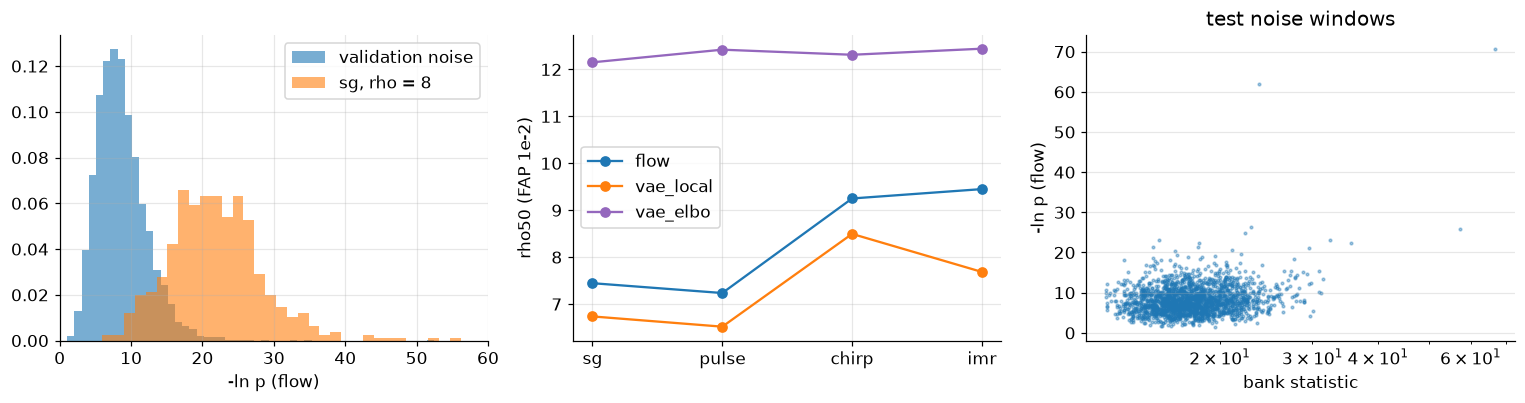

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(ST["val"]["flow"], bins=80, alpha=.6, label="validation noise", density=True); ax[0].hist(ST[("sg", 8)]["flow"], bins=40, alpha=.6, label="sg, rho = 8", density=True); ax[0].set_xlabel("-ln p (flow)"); ax[0].legend(); ax[0].set_xlim(0, 60)
for det, c in (("flow", "C0"), ("vae_local", "C1"), ("vae_elbo", "C4")):
    sub = R[(R.FAP == 1e-2) & (R.model.str.contains({"flow": "flow", "vae_local": "local", "vae_elbo": "ELBO"}[det]))]; ax[1].plot(range(len(sub)), sub.rho50, "o-", color=c, label=det)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(list(MORPHS) + ["imr"]); ax[1].set_ylabel("rho50 (FAP 1e-2)"); ax[1].legend()
ax[2].scatter(bank[::4], ST["test"]["flow"][::4], s=3, alpha=.4); ax[2].set_xscale("log"); ax[2].set_xlabel("bank statistic"); ax[2].set_ylabel("-ln p (flow)"); ax[2].set_title("test noise windows")
fig.tight_layout(); g.savefig(fig, "fig33_unsupervised"); plt.show()
g.save_json(dict(rho50=R.to_dict("records"), overlap=OV.reset_index().to_dict("records")), "33_summary.json")

## Output and next step

`results/33_summary.json`, `figures/fig33_unsupervised`. Next: 2-D CNN and ResNet-1D variants, and a graph neural network on time-frequency pixels.